# Q6 - Predict `still_active` (churn model)

Question: will this player still be active?

Assumption (to confirm with the data owner): `still_active` was computed after the end of the match log (2026-03-03). If that is true, using recency (days since last match) is fair, not leakage.

Some players do not fit: 91 are flagged active but have not played for 90+ days. We treat them as label noise and check their impact in section 5.

We compare 3 feature sets on the same players:
- **Behaviour only**: how the player plays, without recency and without volume.
- **Full history**: every player feature, including recency and volume.
- **MAIN**: full history + activity in the last 7 / 14 / 30 days.

We also try an **early-warning model** that only uses a new player's first 14 days.

Method: 20% of the players are kept aside for the final test, and 5-fold cross-validation on the rest. Main metric: ROC-AUC (0.5 = random, 1 = perfect).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))  # not needed after `pip install -e .`

from ubi_churn.config import DataCatalog, load_params

catalog = DataCatalog.from_config()  # conf/base/catalog.yml
params = load_params()  # conf/base/parameters.yml

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns

from ubi_churn.utils import exploration as ex
from ubi_churn.utils import features as fe
from ubi_churn.utils import ml

ex.set_plot_style()
pl.Config.set_tbl_cols(40)
pl.Config.set_tbl_rows(40)

MS: dict = params['model_selection']
TARGET: str = params['target']
SEED: int = MS['seed']
RECENCY: list[str] = MS['recency']
LIFETIME: list[str] = MS['lifetime']  # lifetime volume / duration / end-of-life state

df_players: pl.DataFrame = catalog.load('player_features').with_columns(pl.col('last_result_win').cast(pl.Float64))
NUMERIC: list[str] = ex.numeric_columns(df_players, exclude=[TARGET])
FEATURES_BEHAVIOUR: list[str] = [c for c in NUMERIC if c not in RECENCY + LIFETIME]
FEATURES_FULL: list[str] = NUMERIC
print(df_players.shape, '| active share:', round(df_players[TARGET].mean(), 3))
print('behaviour only:', len(FEATURES_BEHAVIOUR), 'features | full history + recency:', len(FEATURES_FULL), 'features')

(840, 72) | active share: 0.419
behaviour only: 43 features | full history + recency: 68 features


## 1. Recent activity features

Activity in the last 7 / 14 / 30 days before the end of the log, and the trend vs the period before.

In [2]:
df_raw: pl.DataFrame = catalog.load('player_matches')
REF_DATE = fe.reference_date(df_raw)
print('end of the log:', REF_DATE)

df_recent: pl.DataFrame = fe.build_recent_windows(df_raw, REF_DATE)
FEATURES_RECENT: list[str] = [c for c in df_recent.columns if c.startswith('r_')]
df_main: pl.DataFrame = df_players.join(df_recent, on='playerid', how='left')
FEATURES_MAIN: list[str] = FEATURES_FULL + FEATURES_RECENT
SILENT: pl.Expr = ml.silent_flag(TARGET, MS['silent_days'])
print(len(FEATURES_RECENT), 'recent-window features | MAIN set:', len(FEATURES_MAIN), 'features | silent "active" players:', df_main.filter(SILENT).height)
df_main.group_by(TARGET).agg(*[pl.col(c).median().round(2) for c in ['r_matches_7d', 'r_matches_14d', 'r_active_days_30d', 'r_trend_14d', 'r_share_ranked_30d']], pl.len())

end of the log:

 2026-03-03 13:54:20.190000+00:00
14 recent-window features | MAIN set: 82 features | silent "active" players: 91


still_active,r_matches_7d,r_matches_14d,r_active_days_30d,r_trend_14d,r_share_ranked_30d,len
bool,f64,f64,f64,f64,f64,u32
true,0.0,0.0,1.0,1.0,0.34,352
false,0.0,0.0,0.0,1.0,0.0,488


Observation :
- Recent activity is low for everyone: the median active player played on 1 day in the last 30 days, the median inactive player on 0.
- 91 players are flagged active but silent for 90+ days.

## 2. Models

From simplest to most complex: a dummy baseline (always predicts the average), one feature only (`days_since_last_match`), logistic regression, random forest and gradient boosting. The code is in `src/ubi_churn/utils/ml.py`.

In [3]:
def evaluate(df: pl.DataFrame, features: list[str], single_feature: str, split: str = 'stratified') -> tuple[pd.DataFrame, dict]:
    # CV on the training part + holdout, for every model of ml.make_models (same split for all feature sets)
    return ml.evaluate_models(
        df, features, single_feature, TARGET, SEED, MS['test_size'], MS['n_folds'], split, params['churn_model']['random_forest'],
    )

## 3. Compare the three feature sets

Same players and same split for all.

In [4]:
SINGLE: str = MS['single_feature']
res_beh, fit_beh = evaluate(df_main, FEATURES_BEHAVIOUR, 'matches_first_30d')
res_full, fit_full = evaluate(df_main, FEATURES_FULL, SINGLE)
res_main, fit_main = evaluate(df_main, FEATURES_MAIN, SINGLE)
cmp = pd.concat({'behaviour only': res_beh, 'full history + recency': res_full, 'MAIN (+ recent windows)': res_main})
cmp.droplevel(1)[['model', 'cv_roc_auc', 'cv_pr_auc', 'test_roc_auc', 'test_pr_auc', 'precision', 'recall']]

,model,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,precision,recall
behaviour only,dummy (prior),0.500 +/- 0.000,0.420 +/- 0.002,0.500,0.417,0.417,1.000
behaviour only,1 feature (matches_first_30d),0.661 +/- 0.031,0.589 +/- 0.045,0.676,0.585,0.458,0.857
behaviour only,logistic regression,0.735 +/- 0.035,0.652 +/- 0.033,0.739,0.637,0.550,0.857
behaviour only,random forest,0.752 +/- 0.030,0.683 +/- 0.031,0.763,0.666,0.590,0.843
behaviour only,gradient boosting,0.747 +/- 0.033,0.691 +/- 0.038,0.742,0.611,0.604,0.829
full history + recency,dummy (prior),0.500 +/- 0.000,0.420 +/- 0.002,0.500,0.417,0.417,1.000
full history + recency,1 feature (days_since_last_match),0.781 +/- 0.026,0.775 +/- 0.030,0.827,0.788,0.714,0.714
full history + recency,logistic regression,0.793 +/- 0.034,0.785 +/- 0.038,0.821,0.795,0.650,0.743
full history + recency,random forest,0.820 +/- 0.025,0.811 +/- 0.023,0.825,0.794,0.700,0.800
full history + recency,gradient boosting,0.813 +/- 0.027,0.809 +/- 0.026,0.828,0.759,0.718,0.729


Observation :
- MAIN random forest: 0.820 ROC-AUC in cross-validation, 0.829 on the test players. Full history gives the same: the last 7 / 14 / 30 days features add nothing.
- `days_since_last_match` alone already gives 0.78: recency does most of the work.
- Behaviour only reaches 0.75: how someone plays tells us something, but knowing when he last played matters more.
- Random forest is the best (or tied) everywhere.

## 4. Short-lived vs established players

Results on the test players, split by number of matches.

In [5]:
BEST: str = MS['best_model']
pd.concat([
    ml.segment_report(fitted, BEST, label, df_players, MS['min_matches_segment'])
    for fitted, label in [(fit_beh, 'behaviour only'), (fit_full, 'full history + recency'), (fit_main, 'MAIN')]
])

,set,segment,players,active share,roc_auc,pr_auc
0,behaviour only,< 10 matches,61,0.148,0.588,0.260
1,behaviour only,10+ matches,107,0.570,0.635,0.690
0,full history + recency,< 10 matches,61,0.148,0.541,0.195
1,full history + recency,10+ matches,107,0.570,0.793,0.838
0,MAIN,< 10 matches,61,0.148,0.562,0.206
1,MAIN,10+ matches,107,0.570,0.801,0.848


Observation :
- Players with 10+ matches: 0.80 ROC-AUC with MAIN, much better than behaviour only (0.64).
- Players with fewer than 10 matches: close to random (0.54-0.59). They are hard to predict, but almost all of them leave anyway.

## 5. Label noise: the silent "active" players

Players flagged active but who have not played for 90+ days. We score the model with and without them.

In [6]:
df_silent: pl.DataFrame = df_main.select('playerid', SILENT)
pd.concat([ml.noise_check(fit_full, BEST, 'full history + recency', df_silent), ml.noise_check(fit_main, BEST, 'MAIN', df_silent)])

,set,players,n,active share,roc_auc,pr_auc
0,full history + recency,all holdout players,168,0.417,0.825,0.794
1,full history + recency,"without silent ""active""",154,0.364,0.893,0.832
0,MAIN,all holdout players,168,0.417,0.829,0.801
1,MAIN,"without silent ""active""",154,0.364,0.899,0.841


Observation :
- Without these players, the score goes from 0.83 to 0.90 ROC-AUC. A good part of the errors comes from the label, not from the model.
- To check with the data owner: are these players really active (games missing from the file) or is the flag wrong?

## 6. Early-warning model: the first 14 days

A different question: can we spot future churners from their first 14 days only? Players who joined less than 14 days before the end of the log are left out.

In [7]:
N_WINDOW: int = MS['n_window']
df_early: pl.DataFrame = fe.build_early_window(df_raw, REF_DATE, N_WINDOW, params['features']['session_gap_min'], TARGET)
FEATURES_EARLY: list[str] = [c for c in df_early.columns if c.startswith('w_')]
print(f'window = first {N_WINDOW} days | eligible players: {df_early.height} of {df_players.height} | active share: {df_early[TARGET].mean():.3f}')
res_early, fit_early = evaluate(df_early, FEATURES_EARLY, 'w_matches')
res_early

window = first 14 days | eligible players: 819 of 840 | active share: 0.415


,model,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,threshold,precision,recall
0,dummy (prior),0.500 +/- 0.000,0.415 +/- 0.004,0.500,0.415,0.41,0.415,1.000
1,1 feature (w_matches),0.655 +/- 0.035,0.562 +/- 0.023,0.629,0.558,0.41,0.438,0.779
2,logistic regression,0.665 +/- 0.036,0.580 +/- 0.041,0.695,0.633,0.35,0.490,0.721
3,random forest,0.684 +/- 0.020,0.581 +/- 0.023,0.703,0.641,0.33,0.505,0.750
4,gradient boosting,0.652 +/- 0.022,0.564 +/- 0.030,0.666,0.620,0.26,0.440,0.809


Observation :
- About 0.68 ROC-AUC (0.70 on the test players), vs 0.655 with the number of games alone. The early signal is weak. We keep it as a side tool for new players.

## 7. Robustness: train on old players, test on new ones

We train on the first 80% of players to join and test on the last 20%.

In [8]:
res_main_c, _ = evaluate(df_main, FEATURES_MAIN, SINGLE, split='cohort')
res_main_c[['model', 'cv_roc_auc', 'test_roc_auc', 'test_pr_auc', 'precision', 'recall']]

,model,cv_roc_auc,test_roc_auc,test_pr_auc,precision,recall
0,dummy (prior),0.500 +/- 0.000,0.500,0.357,0.357,1.000
1,1 feature (days_since_last_match),0.814 +/- 0.039,0.787,0.722,0.367,0.967
2,logistic regression,0.794 +/- 0.028,0.790,0.628,0.533,0.800
3,random forest,0.827 +/- 0.022,0.802,0.713,0.490,0.833
4,gradient boosting,0.811 +/- 0.027,0.773,0.703,0.524,0.717


Observation :
- Random forest gets 0.802 on the newest players, close to the random split. `days_since_last_match` alone gets 0.787, so the model still adds little over recency.
- The test group is small (168 players), so these numbers move a bit.

## 8. Which features does the model use?

We shuffle one feature at a time and see how much the score drops.

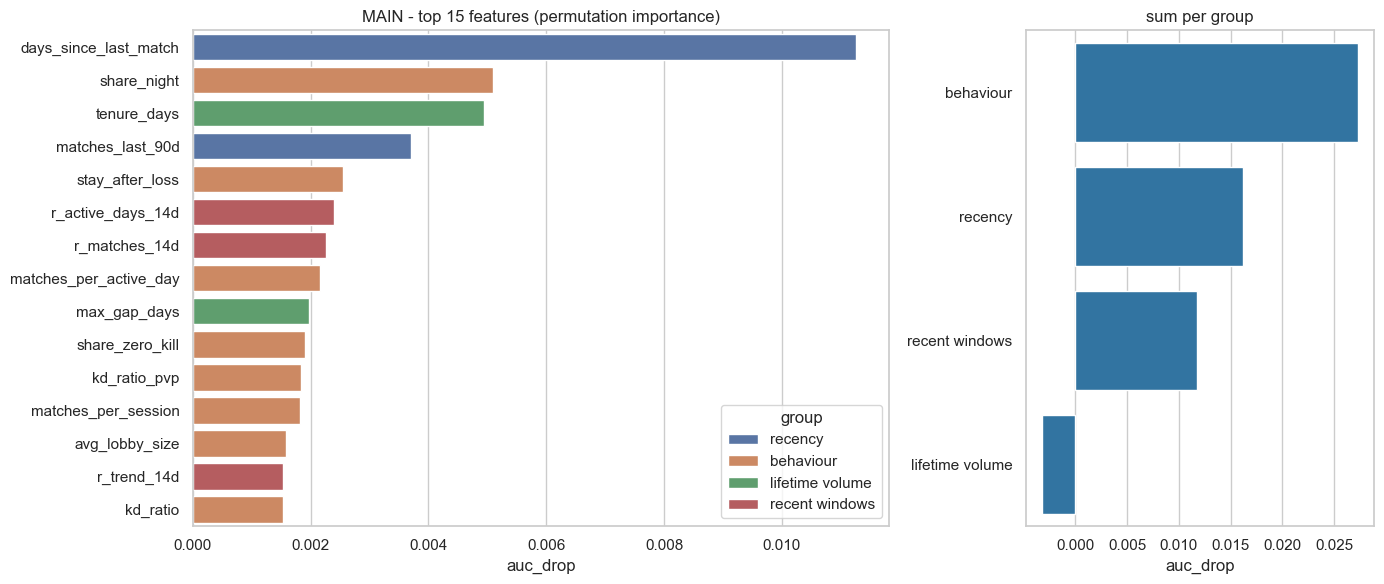

,feature,auc_drop,std,group
0,days_since_last_match,0.0113,0.0067,recency
46,share_night,0.0051,0.0031,behaviour
4,tenure_days,0.0049,0.0037,lifetime volume
2,matches_last_90d,0.0037,0.0059,recency
42,stay_after_loss,0.0025,0.0013,behaviour
73,r_active_days_14d,0.0024,0.0018,recent windows
69,r_matches_14d,0.0023,0.0028,recent windows
10,matches_per_active_day,0.0022,0.0010,behaviour
13,max_gap_days,0.0020,0.0016,lifetime volume
25,share_zero_kill,0.0019,0.0006,behaviour


In [9]:
GROUP_OF: dict[str, str] = {**{c: 'recency' for c in RECENCY}, **{c: 'lifetime volume' for c in LIFETIME}, **{c: 'recent windows' for c in FEATURES_RECENT}}
df_imp: pd.DataFrame = ml.permutation_importance_table(fit_main, BEST, SEED, GROUP_OF)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(data=df_imp.head(15), y='feature', x='auc_drop', hue='group', dodge=False, ax=axes[0])
axes[0].set_title('MAIN - top 15 features (permutation importance)')
axes[0].set_ylabel('')
sns.barplot(data=df_imp.groupby('group', as_index=False)['auc_drop'].sum().sort_values('auc_drop', ascending=False), y='group', x='auc_drop', ax=axes[1], color='tab:blue')
axes[1].set_title('sum per group')
axes[1].set_ylabel('')
fig.tight_layout()
plt.show()
df_imp.head(15).round(4)

Observation :
- `days_since_last_match` is by far the most important, then night play, how long they played, matches in the last 90 days and replaying after a loss.
- Many features are redundant, so each one alone only drops the score a little.
- Skill (win rate, K/D) is not at the top, as seen in notebook 05.

## 9. SHAP: what pushes the prediction?

Each dot is a test player. A dot on the right raises the churn risk, on the left lowers it. Red = high value of the feature. We show the MAIN model and the behaviour-only model.

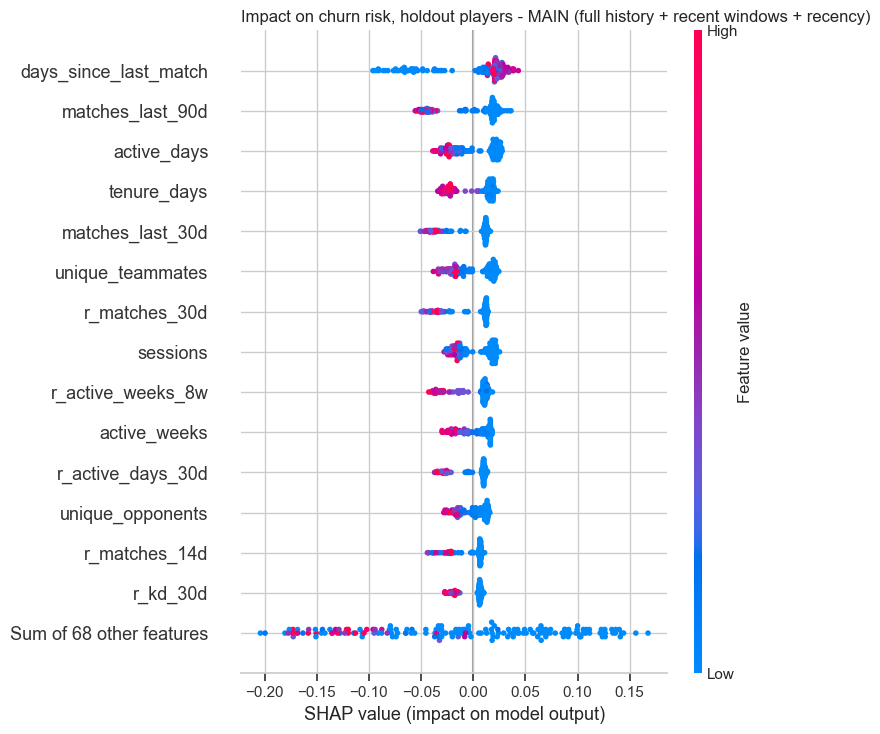

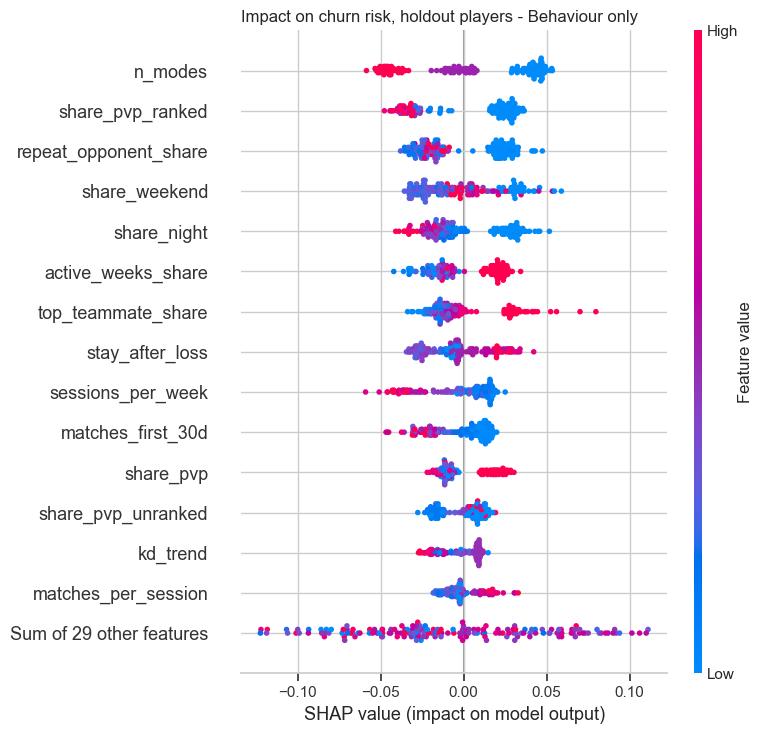

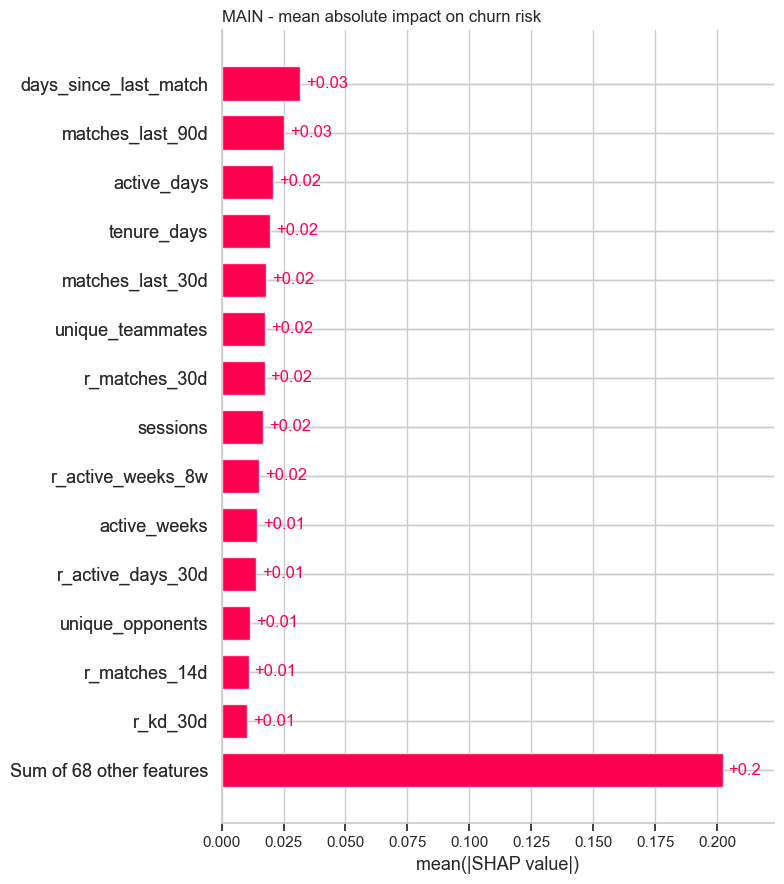

In [10]:
import shap


def holdout_shap(fitted: dict, model_name: str) -> shap.Explanation:
    # SHAP values on the churn risk for the holdout players of one fitted model
    f = fitted[model_name]
    return ml.shap_churn(f['model'], fitted['_data']['X_te'][f['cols']])


for fitted, title in [(fit_main, 'MAIN (full history + recent windows + recency)'), (fit_beh, 'Behaviour only')]:
    ml.plot_shap_summary(holdout_shap(fitted, BEST), f'Impact on churn risk, holdout players - {title}', max_display=15, bar=False)
shap.plots.bar(holdout_shap(fit_main, BEST), max_display=15, show=False)
plt.title('MAIN - mean absolute impact on churn risk', loc='left')
plt.tight_layout()
plt.show()

## Conclusion

- Best model: random forest on the full history, about 0.82 ROC-AUC (0.83 on the test players, 0.90 without the silent "active" players).
- Recency does most of the work: one feature alone gives 0.78. Behaviour alone gives 0.75.
- The label limits the score: we need to confirm with the data owner how `still_active` is computed.
- The 14-day early-warning model is weak (0.68): a side tool for new players.